In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, json

SEED = 42
TARGET = 'stroke'
pd.set_option('display.max_columns', None)

# Modul A - Data Understanding & EDA
## A.1 memuat data

In [33]:
df_raw = pd.read_csv('healthcare-dataset-stroke-data.csv')
df = df_raw.copy()
print('Ukuran dataset:', df.shape)
df.sample(5)

Ukuran dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
198,18937,Male,79.0,0,0,Yes,Private,Rural,114.77,NaN,formerly smoked,1
1902,67942,Male,21.0,0,0,No,Private,Rural,65.09,23.5,never smoked,0
2371,61573,Male,25.0,0,0,No,Private,Rural,65.77,23.7,smokes,0
93,37726,Female,80.0,1,0,Yes,Self-employed,Urban,68.56,26.2,Unknown,1
2893,52164,Male,29.0,0,0,Yes,Private,Urban,193.81,46.8,never smoked,0


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


**Informasi yang di dapat**
- **Label** = stroke (0 = tidak, 1 = iya)
- **Numerik** = age, avg_glucose_level, bmi
- **Kategorikal** = gender, ever_merried, work_type, Residence_type, smmoking_status
- **Biner (0/1)** = hypertension, heart_disease
- **Bukan fitur (yang akan dihapus)** = id, tidak ada kaitannya dengan stroke

## A.2 Cek label pertama kali

stroke
0    4861
1     249
Name: count, dtype: int64

Persentase stroke: 4.87%


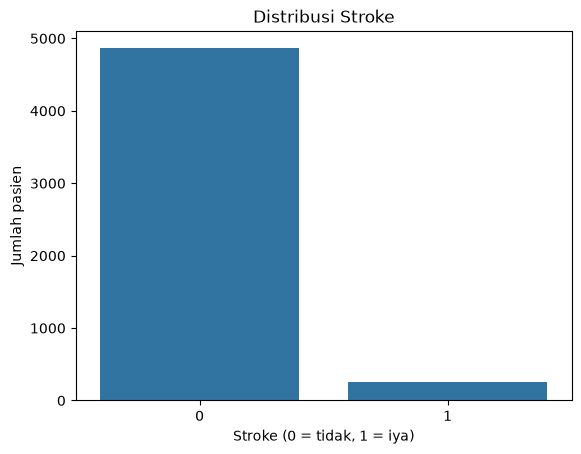

In [35]:
print(df[TARGET].value_counts())
print(f'\nPersentase stroke: {df[TARGET].mean() * 100:.2f}%')

sns.countplot(x=TARGET, data=df)
plt.title('Distribusi Stroke')
plt.xlabel('Stroke (0 = tidak, 1 = iya)')
plt.ylabel('Jumlah pasien')
plt.show()

**Insight - Data yang tidak seimbang (±95 : 5)** hanya 249 dari 5.100 pasien (4.87%) yang stroke.

## A.3 Audit kualitas data

In [36]:
print('Missing per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])

print('\nDuplikat baris    :', df.duplicated().sum())
print('Duplikat id pasien:', df['id'].duplicated().sum())

for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f'\n{col}:', df[col].value_counts().to_dict())

Missing per kolom:
bmi    201
dtype: int64

Duplikat baris    : 0
Duplikat id pasien: 0

gender: {'Female': 2994, 'Male': 2115, 'Other': 1}

ever_married: {'Yes': 3353, 'No': 1757}

work_type: {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}

Residence_type: {'Urban': 2596, 'Rural': 2514}

smoking_status: {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


In [37]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [38]:
print('BMI > 60:', (df['bmi'] > 60).sum(), 'baris (maks:', df['bmi'].max(), ')')
print('Usia < 1 tahun:', (df['age'] < 1).sum(), 'baris (Bayi)')

kosong = df['bmi'].isna()
print(f'\nStroke saat BMI kosong : {df.loc[kosong, TARGET].mean() * 100:.1f}%')
print(f'Stroke saat BMI terisi : {df.loc[~kosong, TARGET].mean() * 100:.1f}%')

hilang  = df.loc[kosong, TARGET].sum() / df[TARGET].sum()
print(f'Jika dropna: {kosong.mean() * 100:.1f}% baris hilang, tapi {hilang * 100:.1f}% kasus stroke ikut hilang')

BMI > 60: 13 baris (maks: 97.6 )
Usia < 1 tahun: 43 baris (Bayi)

Stroke saat BMI kosong : 19.9%
Stroke saat BMI terisi : 4.3%
Jika dropna: 3.9% baris hilang, tapi 16.1% kasus stroke ikut hilang


**Keputusan cleaning**
- id = drop kolom, karena tidak ada hubungannya dengan stroke
- gender = other = drop baris, 1 data dari other tidak bisa untuk dipelajari
- bmi kosong = jangan di drop tapi di isi dnegan median dari data latih, karena kalau di drop akan menghilangkan 16% kasus stroke
- bmi > 60 = dibiarkan, karena mungkin pasien terjadi penyakit obesitas yang esktrem
- smoking_status - unkown = dibuat menjadi kategori tersendiri, karena jika di drop akan membuang data yang banyak
- usia < 1 = dibuat kategori sendiri, karena kemungkinan itu adalah bayi
- Duplikat = tidak ada duplikat data 

In [40]:
df = df_raw.drop(columns=['id'])
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print('Ukuran dataset setelah cleaning:', df.shape)
print('kolom:', df.columns.tolist())

Ukuran dataset setelah cleaning: (5109, 11)
kolom: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


# A.4 EDA

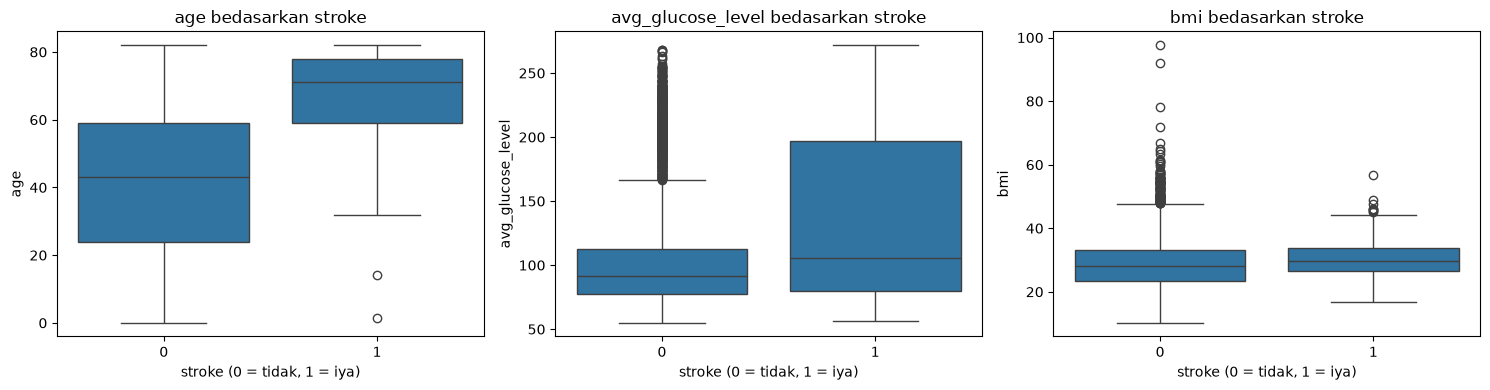

         age  avg_glucose_level   bmi
stroke                               
0       43.0             91.465  28.0
1       71.0            105.220  29.7


In [42]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(f'{col} bedasarkan stroke')
    ax.set_xlabel('stroke (0 = tidak, 1 = iya)')
plt.tight_layout()
plt.show()
print(df.groupby(TARGET)[num_cols].median())

**Insight - Usia adalah pembeda yang terkuat.** Median usia 71 tahun(stroke) vs 43 tahun(tidak). Gula darah lebih tinggi (105 vs 91). BMI hampir sama (29,7 vs 28), jadi diduga fiturnya lemah.Titik yang diatas dari gula darang adalah outlier statistik, bukan data yang salah. Itu adalah kelompok gula darah tinggi(kemungkinan adalah pengidap diabetes), jadi dipertahankan saja.

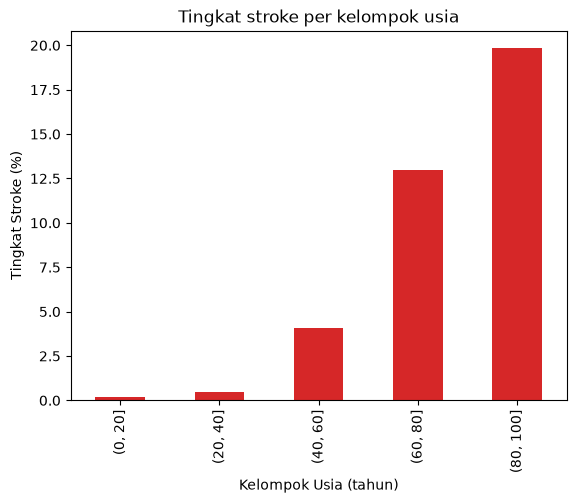

age
(0, 20]       0.2
(20, 40]      0.5
(40, 60]      4.1
(60, 80]     13.0
(80, 100]    19.8
Name: stroke, dtype: float64


In [45]:
kelompok_usia = pd.cut(df['age'], bins=[0, 20, 40, 60, 80, 100])
tingkat = df.groupby(kelompok_usia, observed=True)[TARGET].mean() * 100
tingkat.plot(kind='bar', color='tab:red')
plt.title('Tingkat stroke per kelompok usia')
plt.xlabel('Kelompok Usia (tahun)')
plt.ylabel('Tingkat Stroke (%)')
plt.show()
print(tingkat.round(1))

**Insight 3 — Makin usia bertambah, makin tinggi risiko stroke.** Di bawah 40 tahun, kurang dari 1% pasien stroke. Di usia 60–80 naik ke 13%, dan di atas 80 tahun sekitar 20%, yaitu 1 dari 5 orang. Risikonya selalu naik dan tidak pernah turun, jadi usia akan menjadi fitur paling penting untuk model.

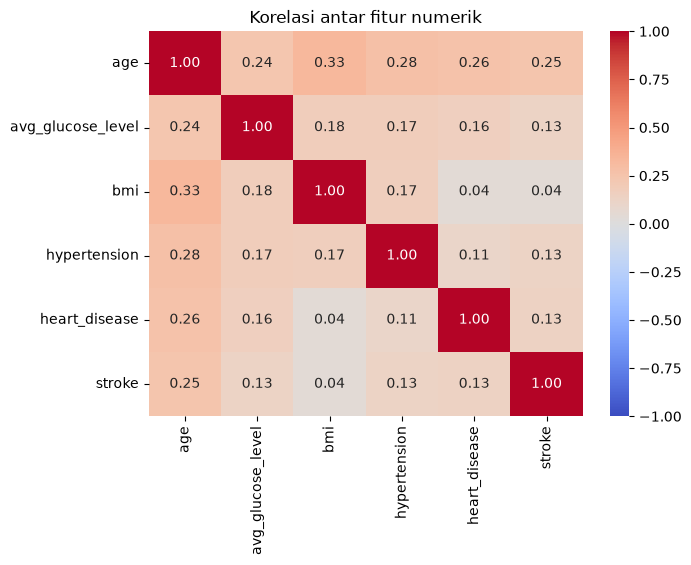

In [46]:
corr = df[num_cols + ['hypertension', 'heart_disease', TARGET]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar fitur numerik')
plt.show()

**Insight - kolerasi dengan label lemah** (tertinggi usia 0,25). Ini wajar untuk label yang jarang. Antar-fitur juga tidak ada korelasi yang tinggi (maks 0,33), jadi tidak ada masalah multikolinearitas untuk regresi logistik.

In [47]:
df.to_csv('df_clean.csv', index=False)
print('tersimpan: df_clean.csv', df.shape, '| BMI kosong', df['bmi'].isna().sum(), '- akan diisi di Modul B')

tersimpan: df_clean.csv (5109, 11) | BMI kosong 201 - akan diisi di Modul B


# Modul B - Klasifikasi
## B.1 Split data stratified dengan 70/15/15 (70 latih/15 validasi/15 uji)